In [1]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

### Load reference

In [2]:
REF = [
    (
        "ProHD2_covariation",
        "Protein\nCo-abundance\n(Fischer\net al. 2025)",
    ),
    (
        "PROPER_share",
        "Multi-cell-line\nPROPER-seq\n(Johnson\net al. 2021)",
    ),
    (
        "PROPER_HEK293T",
        "HEK293T\nPROPER-seq\n(Johnson\net al. 2021)",
    ),
    (
        "ImageTop1",
        "HEK293T\nimage\n(Cho\net al. 2022)",
    ),
]

In [3]:
def load_reference_pairs(path):
    ref = pd.read_csv(path, sep="\t")
    ref_pair = []
    for row in ref.values:
        ref_pair.append(row[0] + "__" + row[1])
    return set(ref_pair)

In [4]:
ref_file_list, ref_label_list = map(list, zip(*REF))
ref_pair_list = [
    load_reference_pairs("../../result/reference/%s.txt" % name)
    for name in ref_file_list
]
n_ref = len(ref_file_list)

### Load PPIs and compute AUROC

In [5]:
PPI = [
    (
        "AP-MS",
        "../../result/HEK293T_HCT116/ppi/FromRaw_BioPlex_HEK293T.ppi"
    ),
    (
        "SEC-MS",
        "../../result/HEK293T_HCT116/ppi/FromRaw_SECMX_HEK293T.ppi"
    ),
    (
        "Init emb",
        "../../result/HEK293T_HCT116/ppi/FromInputConcat_HEK293T.ppi.Percent05"
    ),
    (
        "Autoencoder",
        "../../result/HEK293T_HCT116/ppi/AEconcat_HEK293T.ppi.Percent05"
    ),
    (
        "CL",
        "../../result/HEK293T_HCT116/ppi/GPSseparate_HEK293T.ppi.Percent05"
    ),
    (
        "CL (context-agnostic)",
        "../../result/HEK293T_HCT116/ppi/GPScombine_HEK293T.ppi.Percent05"
    ),
    (
        "Subtract",
        "../../result/HEK293T_HCT116/ppi/promergesubtract_HCT116anchor_HEK293T.ppi.Percent05"
    ),
    (
        "ProMERGE",
        "../../result/HEK293T_HCT116/ppi/promergeclub_HCT116anchor_HEK293T.ppi.Percent05"
    ),
]

In [6]:
label_list = [label for label, _ in PPI]
n_ppi = len(label_list)

In [7]:
# ROC curves are resampled on one FPR grid to keep the PDF small
FPR_GRID = np.linspace(0, 1, 2001)

score_dict = {}
label_dict = {}
auc_emb = np.empty((n_ppi, n_ref))
tpr_emb = np.empty((n_ppi, n_ref, len(FPR_GRID)))

for ii, (label, name) in enumerate(PPI):
    ppi = pd.read_csv(name, sep="\t", header=None)
    
    score_dict[label] = ppi[1].values.astype(np.float64)
    label_dict[label] = [
        ppi[0].isin(ref_pair).astype(np.int8).values
        for ref_pair in ref_pair_list
    ]

    for rr in range(n_ref):
        auc_emb[ii, rr] = roc_auc_score(
            label_dict[label][rr], 
            score_dict[label]
        )

        fpr, tpr, _ = roc_curve(
            label_dict[label][rr],
            score_dict[label],
        )
        tpr_emb[ii, rr] = np.interp(FPR_GRID, fpr, tpr)

In [8]:
pd.DataFrame(auc_emb, index=label_list, columns=ref_file_list)

,ProHD2_covariation,PROPER_share,PROPER_HEK293T,ImageTop1
AP-MS,0.519769,0.366425,0.366253,0.729398
SEC-MS,0.674813,0.587208,0.592491,0.744272
Init emb,0.638407,0.525903,0.525409,0.705727
Autoencoder,0.631336,0.605957,0.604498,0.695123
CL,0.713747,0.626469,0.628692,0.642876
CL (context-agnostic),0.678291,0.631688,0.630289,0.711467
Subtract,0.743388,0.647807,0.652816,0.819199
ProMERGE,0.761797,0.662043,0.666221,0.831628


### plot

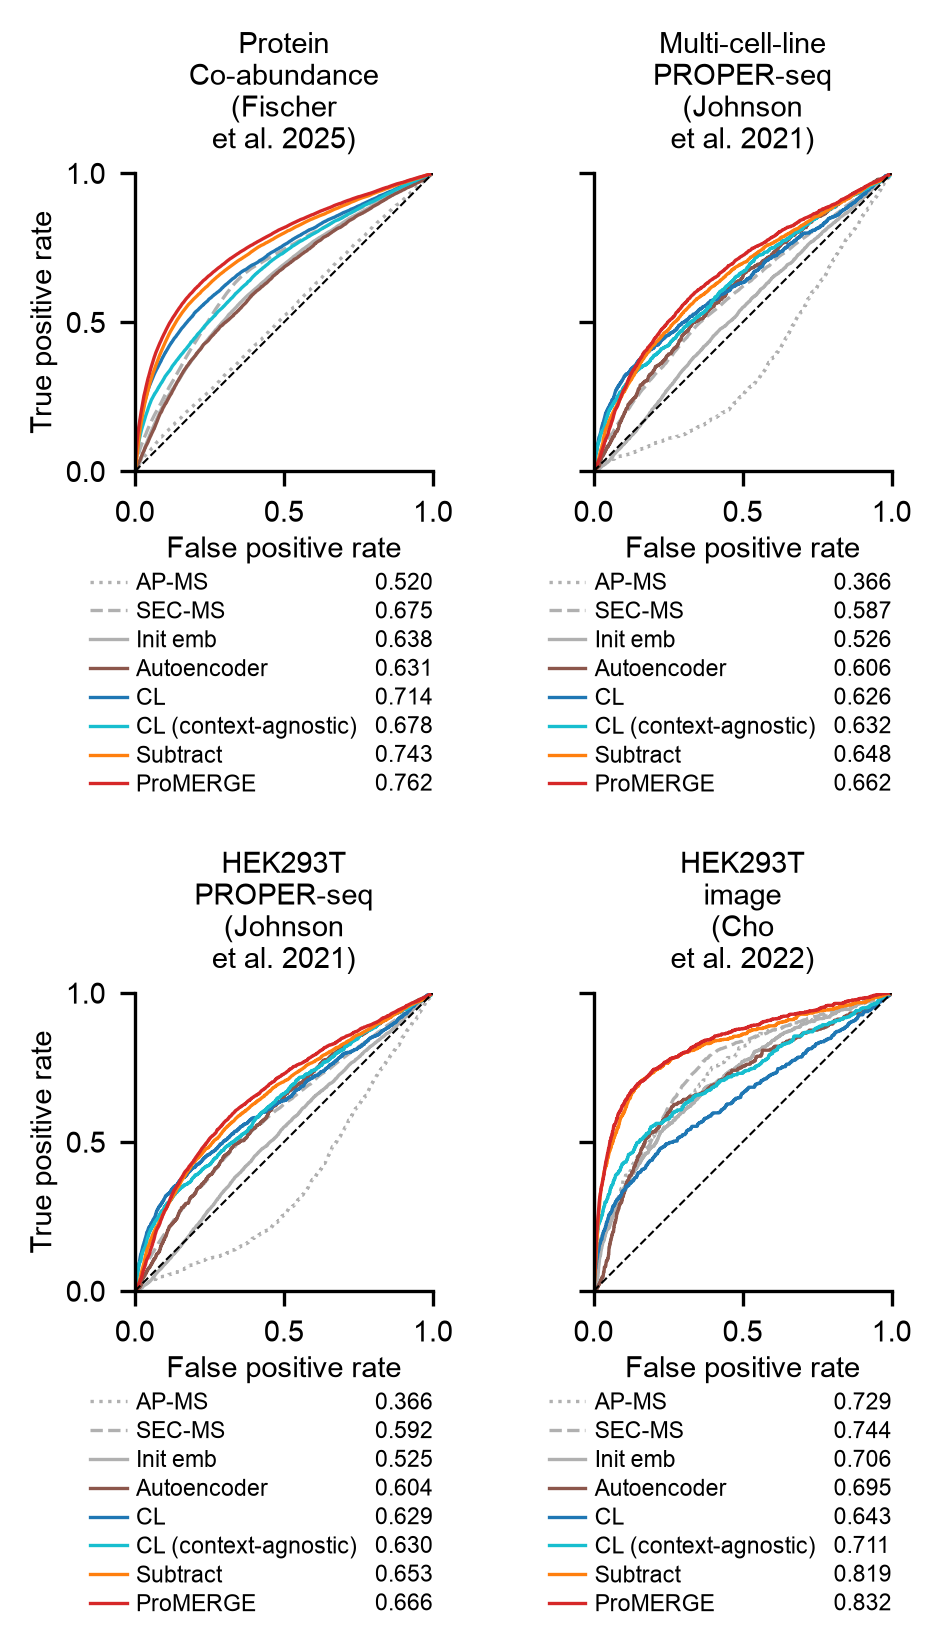

In [9]:
color_list = [
    "#b0b0b0", "#b0b0b0", "#b0b0b0",
    "tab:brown", "tab:blue", "tab:cyan",
    "tab:orange", "tab:red",
]
linestyle_list = [
    ":", "--", "-",
    "-", "-", "-",
    "-", "-",
]

# init plot
plt.style.use("/home/jig049/misc/style.mplstyle")
fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    sharey=True,
    figsize=(3.2, 5.4),
    dpi=300,
)
fig.subplots_adjust(
    left=0.13,
    right=0.99,
    bottom=0.21,
    top=0.90,
    hspace=1.75,
    wspace=0.25,
)

# main plot
for rr, ax in enumerate(axes.flat):
    handle_list = []
    for ii, method_label in enumerate(label_list):
        line, = ax.plot(
            FPR_GRID,
            tpr_emb[ii, rr],
            color=color_list[ii],
            linestyle=linestyle_list[ii],
            lw=0.8,
        )
        handle_list.append(line)

    # random ranking
    ax.plot(
        [0, 1],
        [0, 1],
        color="black",
        lw=0.5,
        linestyle="--",
    )

    # axis and tick
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1])
    ax.set_xticks([0, 0.5, 1])
    ax.set_yticks([0, 0.5, 1])
    ax.tick_params(axis="both", labelsize=7)
    ax.set_xlabel("False positive rate", labelpad=2, fontsize=7)
    ax.set_title(ref_label_list[rr], fontsize=7)
    ax.set_aspect("equal")
    ax.spines[["right", "top"]].set_visible(False)

    # legend
    legend_kw = dict(
        fontsize=5.5,
        frameon=False,
        labelspacing=0.3,
        borderpad=0,
        borderaxespad=0,
        labelcolor="black",
    )

    leg_auc = ax.legend(
        handle_list,
        [f"{auc:.3f}" for auc in auc_emb[:, rr]],
        loc="upper right",
        bbox_to_anchor=(1.0, -0.34),
        bbox_transform=ax.transAxes,
        handlelength=0,
        handletextpad=0,
        **legend_kw,
    )

    for handle in leg_auc.legend_handles:
        handle.set_visible(False)

    ax.add_artist(leg_auc)
    ax.legend(
        handle_list,
        label_list,
        loc="upper left",
        bbox_to_anchor=(-0.15, -0.34),
        bbox_transform=ax.transAxes,
        handlelength=1.6,
        handletextpad=0.4,
        **legend_kw,
    )

for ax in axes[:, 0]:
    ax.set_ylabel("True positive rate", labelpad=2, fontsize=7)

plt.savefig("./figS5_AUROC.pdf", bbox_inches="tight", transparent=True)